In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

df = pd.read_csv('data\\clean\\cleaned_data.csv')
df.head()

,ride_id,rideable_type,started_at,ended_at,start_station_name,start_station_id,end_station_name,end_station_id,start_lat,start_lng,end_lat,end_lng,member_casual,ride_length,day_of_week
0,AAED255E1310E516,classic_bike,2025-10-27 08:19:53.208,2025-10-27 08:25:53.481,Wells St & Polk St,CHI00606,Franklin St & Washington St,CHI02074,41.872732,-87.633516,41.883180,-87.635110,member,00:06:00,Monday
1,F90C86BF3BB85040,classic_bike,2025-10-14 07:42:55.465,2025-10-14 08:04:08.663,Racine Ave & Wrightwood Ave,CHI00506,McClurg Ct & Ohio St,CHI00330,41.928887,-87.658971,41.892592,-87.617289,member,00:21:13,Tuesday
2,90429D9729A3EE8E,classic_bike,2025-10-12 08:18:23.613,2025-10-12 08:28:38.983,Clinton St & 18th St,CHI00235,Desplaines St & Jackson Blvd,CHI00518,41.857950,-87.640826,41.878119,-87.643948,casual,00:10:15,Sunday
3,C8433F9B78A1E63D,electric_bike,2025-10-14 07:45:56.471,2025-10-14 08:07:24.447,Pine Grove Ave & Irving Park Rd,CHI00482,Wells St & Huron St,CHI00294,41.954398,-87.647997,41.894795,-87.634374,member,00:21:27,Tuesday
4,62F3C413C442C154,electric_bike,2025-10-19 10:08:45.138,2025-10-19 10:12:34.771,Pine Grove Ave & Irving Park Rd,CHI00482,Sheridan Rd & Montrose Ave,CHI00290,41.954365,-87.647929,41.961670,-87.654640,member,00:03:49,Sunday


In [2]:
df['started_at'] = pd.to_datetime(df['started_at'])
df['ended_at'] = pd.to_datetime(df['ended_at'])
df['ride_length'] = ((df['ended_at'] - df['started_at']).dt.total_seconds() / 60).round(2)
df[['started_at','ended_at','ride_length']].head()

,started_at,ended_at,ride_length
0,2025-10-27 08:19:53.208,2025-10-27 08:25:53.481,6.00
1,2025-10-14 07:42:55.465,2025-10-14 08:04:08.663,21.22
2,2025-10-12 08:18:23.613,2025-10-12 08:28:38.983,10.26
3,2025-10-14 07:45:56.471,2025-10-14 08:07:24.447,21.47
4,2025-10-19 10:08:45.138,2025-10-19 10:12:34.771,3.83


In [3]:
df['day_of_week'] = df['started_at'].dt.day_name()
df[['started_at', 'ride_length', 'day_of_week']].head()

,started_at,ride_length,day_of_week
0,2025-10-27 08:19:53.208,6.00,Monday
1,2025-10-14 07:42:55.465,21.22,Tuesday
2,2025-10-12 08:18:23.613,10.26,Sunday
3,2025-10-14 07:45:56.471,21.47,Tuesday
4,2025-10-19 10:08:45.138,3.83,Sunday


In [4]:
df.describe(include='all').T

,count,unique,top,freq,mean,min,25%,50%,75%,max,std
ride_id,6166305,6166305,AAED255E1310E516,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
rideable_type,6166305,2,electric_bike,4387337,NaN,NaN,NaN,NaN,NaN,NaN,NaN
started_at,6166305,NaN,NaN,NaN,2026-05-10 00:49:40.117412,2025-09-30 10:13:36.262000,2026-03-08 14:31:54.987000,2026-06-07 23:05:44.345000,2026-08-04 17:39:20.730000,2026-09-30 23:59:38.090000,NaN
ended_at,6166305,NaN,NaN,NaN,2026-05-10 01:03:37.052966,2025-10-01 00:00:07.199000,2026-03-08 14:50:57.150000,2026-06-07 23:21:43.814000,2026-08-04 17:53:48.735000,2026-09-30 23:59:48.043000,NaN
start_station_name,6166305,1989,Navy Pier,1355985,NaN,NaN,NaN,NaN,NaN,NaN,NaN
start_station_id,6166305,1988,CHI01747,1355985,NaN,NaN,NaN,NaN,NaN,NaN,NaN
end_station_name,6166305,2025,Navy Pier,1415882,NaN,NaN,NaN,NaN,NaN,NaN,NaN
end_station_id,6166305,2025,CHI01747,1415882,NaN,NaN,NaN,NaN,NaN,NaN,NaN
start_lat,6166305.0,NaN,NaN,NaN,41.904596,41.64,41.882752,41.9,41.93,42.07,0.044245
start_lng,6166305.0,NaN,NaN,NaN,-87.646933,-87.91,-87.66,-87.642884,-87.63,-87.52,0.026942


# Finding Data Distribution

In [5]:
duration_summary = df.groupby('member_casual')['ride_length'].agg(
    Total_Rides='count',
    Mean_Mins='mean',
    Median_Mins='median',
    Std_Dev='std'
).round(2)
duration_summary['Ride_Share (%)'] = (
    duration_summary['Total_Rides'] / len(df) * 100
).round(2)
duration_summary

,Total_Rides,Mean_Mins,Median_Mins,Std_Dev,Ride_Share (%)
member_casual,,,,,
casual,2184710,17.61,10.75,35.82,35.43
member,3981595,11.94,8.51,21.90,64.57


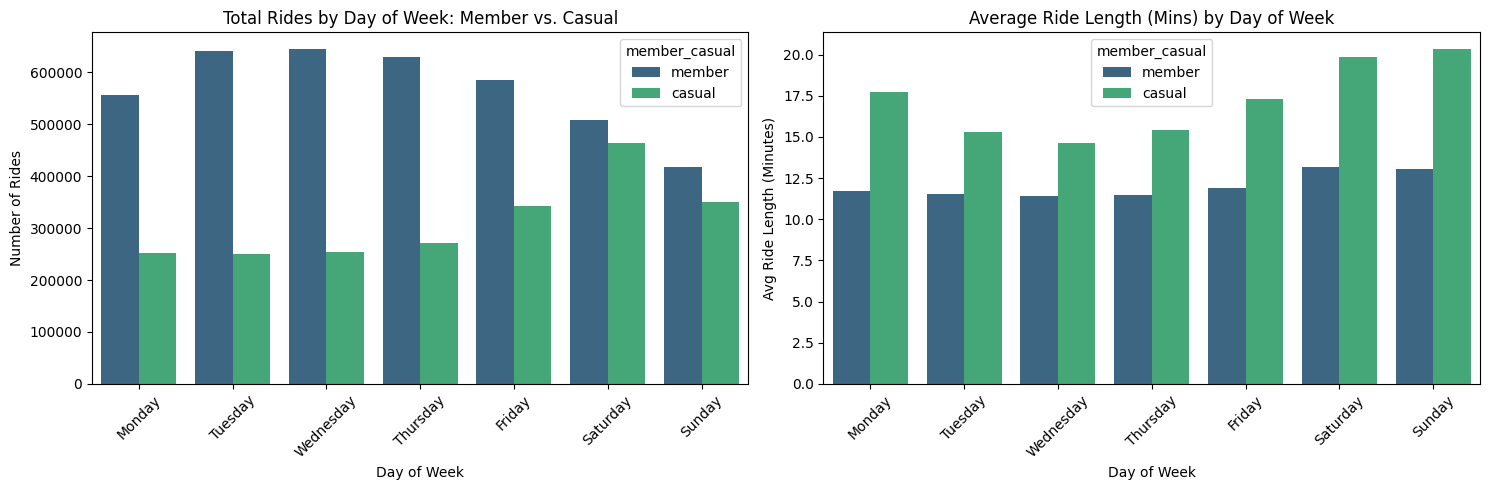

In [6]:
days_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
df['day_of_week'] = pd.Categorical(df['day_of_week'], categories=days_order, ordered=True)
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
sns.countplot(
    data=df, 
    x='day_of_week', 
    hue='member_casual', 
    palette='viridis', 
    ax=axes[0]
)
axes[0].set_title('Total Rides by Day of Week: Member vs. Casual')
axes[0].set_xlabel('Day of Week')
axes[0].set_ylabel('Number of Rides')
axes[0].tick_params(axis='x', rotation=45)
sns.barplot(
    data=df, 
    x='day_of_week', 
    y='ride_length', 
    hue='member_casual', 
    estimator='mean', 
    errorbar=None, 
    palette='viridis', 
    ax=axes[1]
)
axes[1].set_title('Average Ride Length (Mins) by Day of Week')
axes[1].set_xlabel('Day of Week')
axes[1].set_ylabel('Avg Ride Length (Minutes)')
axes[1].tick_params(axis='x', rotation=45)
plt.tight_layout()
plt.show()

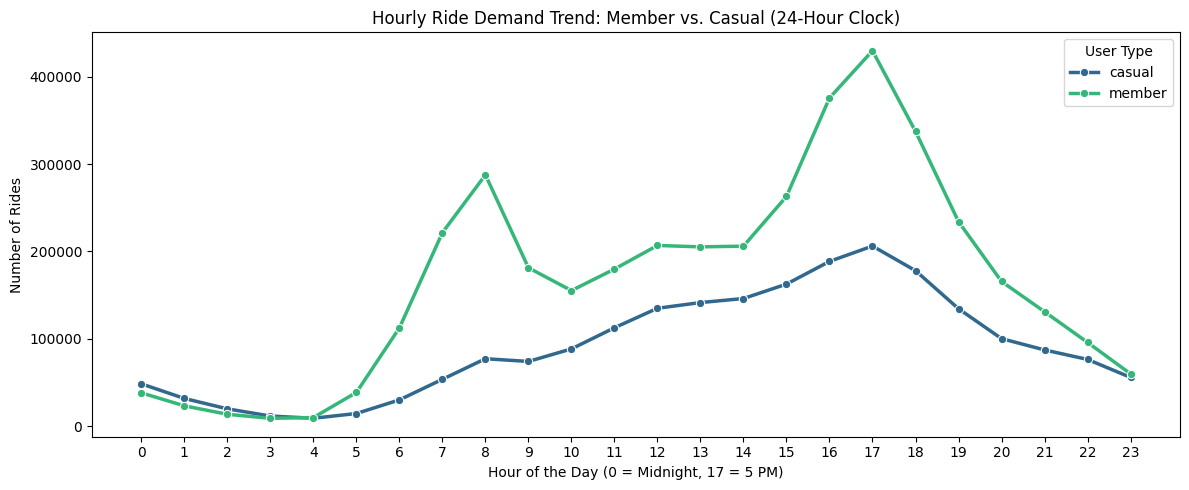

In [26]:
hourly_counts = df.groupby(['hour', 'member_casual'], observed=False).size().reset_index(name='ride_count')

plt.figure(figsize=(12, 5))
sns.lineplot(
    data=hourly_counts, 
    x='hour', 
    y='ride_count', 
    hue='member_casual', 
    palette='viridis', 
    marker='o',       
    linewidth=2.5
)

plt.title('Hourly Ride Demand Trend: Member vs. Casual (24-Hour Clock)')
plt.xlabel('Hour of the Day (0 = Midnight, 17 = 5 PM)')
plt.ylabel('Number of Rides')
plt.xticks(range(0, 24)) 
plt.legend(title='User Type')
plt.tight_layout()
plt.show()

In [8]:
bike_pref = pd.crosstab(
    df['rideable_type'], 
    df['member_casual'], 
    normalize='columns'
).round(4) * 100
bike_pref


member_casual,casual,member
rideable_type,,
classic_bike,24.92,31.01
electric_bike,75.08,68.99


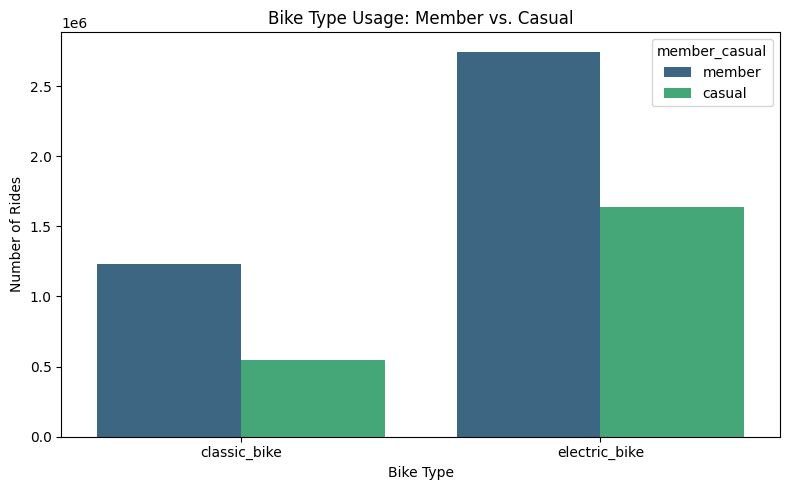

In [9]:
plt.figure(figsize=(8, 5))
sns.countplot(data=df, x='rideable_type', hue='member_casual', palette='viridis')
plt.title('Bike Type Usage: Member vs. Casual')
plt.xlabel('Bike Type')
plt.ylabel('Number of Rides')
plt.tight_layout()
plt.show()

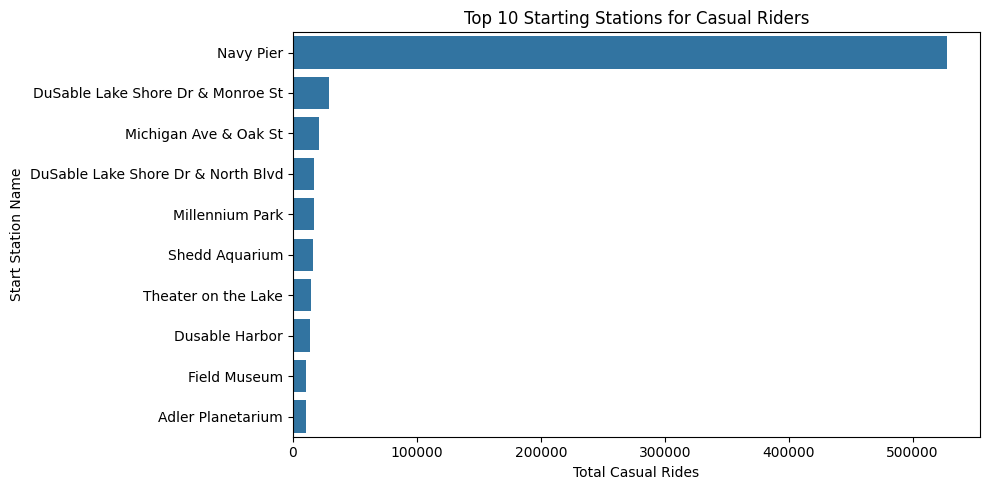

In [10]:
top_casual_stations = (
    df[df['member_casual'] == 'casual']['start_station_name']
    .dropna()
    .value_counts()
    .head(10)
)

plt.figure(figsize=(10, 5))
sns.barplot(
    x=top_casual_stations.values, 
    y=top_casual_stations.index, 
)
plt.title('Top 10 Starting Stations for Casual Riders')
plt.xlabel('Total Casual Rides')
plt.ylabel('Start Station Name')
plt.tight_layout()
plt.show()

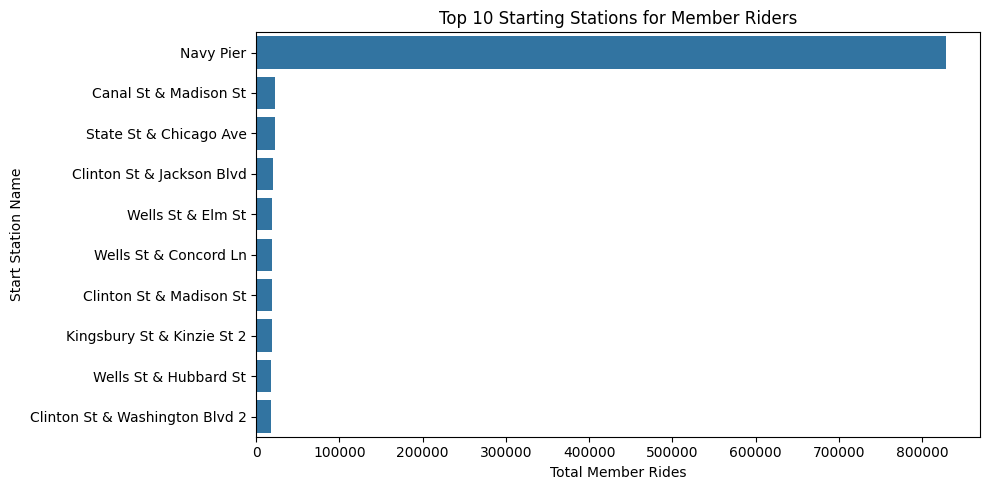

In [11]:
top_casual_stations = (
    df[df['member_casual'] == 'member']['start_station_name']
    .dropna()
    .value_counts()
    .head(10)
)

plt.figure(figsize=(10, 5))
sns.barplot(
    x=top_casual_stations.values, 
    y=top_casual_stations.index, 
)
plt.title('Top 10 Starting Stations for Member Riders')
plt.xlabel('Total Member Rides')
plt.ylabel('Start Station Name')
plt.tight_layout()
plt.show()

# Finding Outliers

In [12]:
percentiles = df['ride_length'].quantile([0.01, 0.05, 0.25, 0.50, 0.75, 0.95, 0.99, 0.999])
percentiles



0.010      0.25000
0.050      2.07000
0.250      5.30000
0.500      9.20000
0.750     16.02000
0.950     37.26000
0.990     78.18000
0.999    246.48392
Name: ride_length, dtype: float64

C:\Users\vireak\AppData\Local\Temp\ipykernel_10700\564086639.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='ride_length', y='member_casual', palette='viridis')


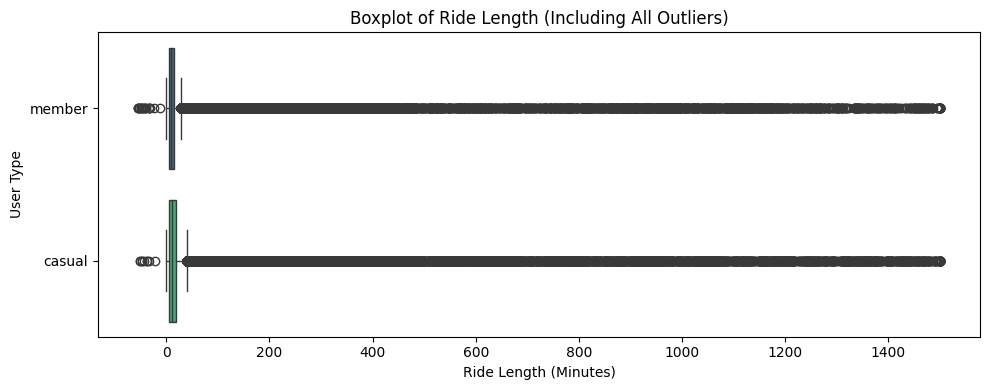

In [13]:
plt.figure(figsize=(10, 4))
sns.boxplot(data=df, x='ride_length', y='member_casual', palette='viridis')
plt.title('Boxplot of Ride Length (Including All Outliers)')
plt.xlabel('Ride Length (Minutes)')
plt.ylabel('User Type')
plt.tight_layout()
plt.show()

In [14]:
Q1 = df['ride_length'].quantile(0.25)
Q3 = df['ride_length'].quantile(0.75)
IQR = Q3 - Q1
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR
iqr_outliers = df[(df['ride_length'] < lower_bound) | (df['ride_length'] > upper_bound)]

print(f"Q1: {Q1:.2f} mins | Q3: {Q3:.2f} mins | IQR: {IQR:.2f} mins")
print(f"IQR Upper Bound Cutoff: {upper_bound:.2f} mins")
print(f"Total IQR Outliers Found: {len(iqr_outliers)} ({len(iqr_outliers)/len(df)*100:.2f}% of data)")

Q1: 5.30 mins | Q3: 16.02 mins | IQR: 10.72 mins
IQR Upper Bound Cutoff: 32.10 mins
Total IQR Outliers Found: 426540 (6.92% of data)


In [15]:
short_outliers = df[df['ride_length'] < 1]
long_outliers = df[df['ride_length'] > 1440]

print(f"False starts (< 1 min): {len(short_outliers)} rides")
print(f"Over 24 hours (> 1440 mins): {len(long_outliers)} rides")
print("\nRides > 24 hours by user type:")
print(long_outliers['member_casual'].value_counts())

False starts (< 1 min): 158831 rides
Over 24 hours (> 1440 mins): 180 rides

Rides > 24 hours by user type:
member_casual
casual    112
member     68
Name: count, dtype: int64


In [16]:
df_clean = df[(df['ride_length'] >= 1) & (df['ride_length'] <= 1440)].copy()

C:\Users\vireak\AppData\Local\Temp\ipykernel_10700\234765794.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


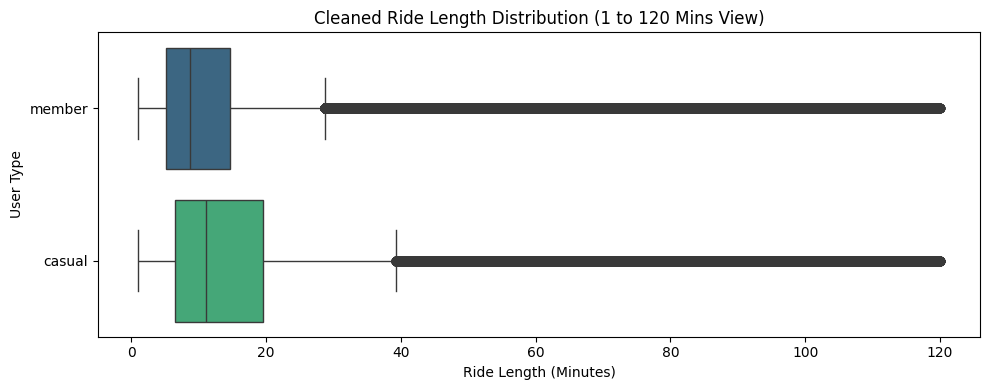

In [17]:
plt.figure(figsize=(10, 4))
sns.boxplot(
    data=df_clean[df_clean['ride_length'] <= 120], 
    x='ride_length', 
    y='member_casual', 
    palette='viridis'
)
plt.title('Cleaned Ride Length Distribution (1 to 120 Mins View)')
plt.xlabel('Ride Length (Minutes)')
plt.ylabel('User Type')
plt.tight_layout()
plt.show()

# Finding Correlation

In [18]:
df_corr = df.copy()
df_corr['is_casual'] = (df_corr['member_casual'] == 'casual').astype(int)
df_corr['is_electric'] = (df_corr['rideable_type'] == 'electric_bike').astype(int)


In [19]:
df_corr['hour'] = df_corr['started_at'].dt.hour
df_corr['day_num'] = df_corr['started_at'].dt.dayofweek # 0 = Monday, 6 = Sunday
df_corr['is_weekend'] = df_corr['day_num'].isin([5, 6]).astype(int)

In [20]:
import numpy as np
lat1, lon1 = np.radians(df_corr['start_lat']), np.radians(df_corr['start_lng'])
lat2, lon2 = np.radians(df_corr['end_lat']), np.radians(df_corr['end_lng'])
dlat, dlon = lat2 - lat1, lon2 - lon1
a = np.sin(dlat/2)**2 + np.cos(lat1) * np.cos(lat2) * np.sin(dlon/2)**2
df_corr['distance_km'] = 6371 * 2 * np.arcsin(np.sqrt(a))   

In [21]:
df_corr.head()

,ride_id,rideable_type,started_at,ended_at,start_station_name,start_station_id,end_station_name,end_station_id,start_lat,start_lng,...,member_casual,ride_length,day_of_week,hour,month,is_casual,is_electric,day_num,is_weekend,distance_km
0,AAED255E1310E516,classic_bike,2025-10-27 08:19:53.208,2025-10-27 08:25:53.481,Wells St & Polk St,CHI00606,Franklin St & Washington St,CHI02074,41.872732,-87.633516,...,member,6.00,Monday,8,October,0,0,0,0,1.169282
1,F90C86BF3BB85040,classic_bike,2025-10-14 07:42:55.465,2025-10-14 08:04:08.663,Racine Ave & Wrightwood Ave,CHI00506,McClurg Ct & Ohio St,CHI00330,41.928887,-87.658971,...,member,21.22,Tuesday,7,October,0,0,1,0,5.308905
2,90429D9729A3EE8E,classic_bike,2025-10-12 08:18:23.613,2025-10-12 08:28:38.983,Clinton St & 18th St,CHI00235,Desplaines St & Jackson Blvd,CHI00518,41.857950,-87.640826,...,casual,10.26,Sunday,8,October,1,0,6,1,2.257526
3,C8433F9B78A1E63D,electric_bike,2025-10-14 07:45:56.471,2025-10-14 08:07:24.447,Pine Grove Ave & Irving Park Rd,CHI00482,Wells St & Huron St,CHI00294,41.954398,-87.647997,...,member,21.47,Tuesday,7,October,0,1,1,0,6.722673
4,62F3C413C442C154,electric_bike,2025-10-19 10:08:45.138,2025-10-19 10:12:34.771,Pine Grove Ave & Irving Park Rd,CHI00482,Sheridan Rd & Montrose Ave,CHI00290,41.954365,-87.647929,...,member,3.83,Sunday,10,October,0,1,6,1,0.983796


In [22]:
corr_features = [
    'ride_length', 
    'distance_km', 
    'is_casual', 
    'is_electric', 
    'is_weekend', 
    'hour', 
    'day_num'
]

corr_matrix = df_corr[corr_features].corr()
corr_matrix.round(3)


,ride_length,distance_km,is_casual,is_electric,is_weekend,hour,day_num
ride_length,1.000,0.250,0.098,-0.104,0.054,0.015,0.045
distance_km,0.250,1.000,-0.019,0.054,0.023,0.012,0.018
is_casual,0.098,-0.019,1.000,0.064,0.149,0.036,0.137
is_electric,-0.104,0.054,0.064,1.000,-0.010,0.003,0.001
is_weekend,0.054,0.023,0.149,-0.010,1.000,-0.048,0.781
hour,0.015,0.012,0.036,0.003,-0.048,1.000,-0.036
day_num,0.045,0.018,0.137,0.001,0.781,-0.036,1.000


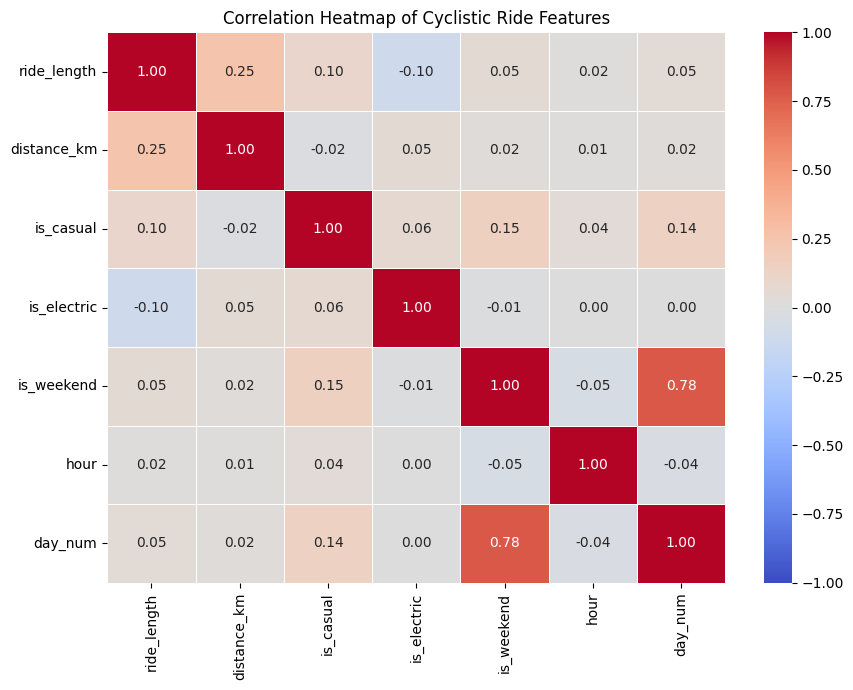

In [23]:
plt.figure(figsize=(9, 7))
sns.heatmap(
    corr_matrix, 
    annot=True, 
    fmt='.2f', 
    cmap='coolwarm', 
    vmin=-1, 
    vmax=1, 
    linewidths=0.5
)
plt.title('Correlation Heatmap of Cyclistic Ride Features')
plt.tight_layout()
plt.show()

In [24]:
df_clean.to_csv('data\\clean\\explored_data.csv')